In [1]:
import sys, os
sys.path.append("..")

import usf

In [2]:
usf_folders = ['C:/Users/au646858/Downloads/USF_Files_dawa river/']

sweeps = []
for usf_folder in usf_folders:
    usf_files = [usf_folder+f for f in os.listdir(usf_folder) if f.endswith('.usf')]
    for usf_file in usf_files:        
        sweeps += usf.Sweep.from_usf(usf_file, combine=False)


data_overview, df_data = usf.sweep2dataframes(sweeps)

# df_data.loc[df_data['time']>1e-3, 'inuse_auto'] = False
# df_data = df_data.sort_values(by=['site_id','system_id', 'gate_id'])

In [3]:
points = set([x.points for x in sweeps])

mega_sweeps = []
for pnts in points:
    mega_sweeps.append(usf.Sweep.combine_sweeps([swp for swp in sweeps if swp.points==pnts]))
lm,hm = mega_sweeps

In [4]:
df_data['include'] = df_data['inuse_auto']

In [5]:
pivot = df_data[df_data['site_id']>=0].pivot_table(
    index=['site_id'],
    columns=['sys_gate'],
    values='dbdt'
)

In [6]:
# Create pivot table with multiple values
pivot_multi = df_data[df_data['site_id']>=0].pivot_table(
    index=['site_id'],
    columns=['sys_gate'],
    values=['dbdt', 'error', 'include']
)

# Flatten the multi-level column names
pivot_multi.columns = [f'{val}_{col}' for val, col in pivot_multi.columns]
pivot_multi

,dbdt_0.0,dbdt_0.01,dbdt_0.02,dbdt_0.03,dbdt_0.04,dbdt_0.05,dbdt_1.0,dbdt_1.01,dbdt_1.02,dbdt_1.03,...,include_1.12,include_1.13,include_1.1400000000000001,include_1.15,include_1.16,include_1.17,include_1.18,include_1.19,include_1.2,include_1.21
site_id,,,,,,,,,,,,,,,,,,,,,
0,0.000008,0.000005,2.960390e-06,1.716670e-06,9.905290e-07,5.755000e-07,1.246170e-06,6.747170e-07,3.695650e-07,2.045410e-07,...,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0
1,0.000005,0.000003,1.777440e-06,1.070710e-06,6.543040e-07,4.038660e-07,8.063070e-07,4.697770e-07,2.770680e-07,1.646370e-07,...,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0
2,0.000004,0.000003,1.760430e-06,1.135900e-06,7.274330e-07,4.618690e-07,8.772410e-07,5.313900e-07,3.197160e-07,1.914410e-07,...,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0
3,0.000006,0.000004,2.421000e-06,1.522140e-06,9.499710e-07,5.866660e-07,1.156850e-06,6.788090e-07,3.943070e-07,2.269800e-07,...,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0
4,0.000004,0.000002,1.545860e-06,9.725170e-07,6.080860e-07,3.786440e-07,7.421770e-07,4.394710e-07,2.611980e-07,1.562060e-07,...,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0
5,0.000002,0.000001,9.014080e-07,5.925550e-07,3.889980e-07,2.556770e-07,4.679400e-07,2.939610e-07,1.851020e-07,1.167700e-07,...,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0
6,0.000004,0.000002,1.409740e-06,8.513620e-07,5.201450e-07,3.211830e-07,6.428770e-07,3.743210e-07,2.214700e-07,1.328950e-07,...,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0
7,0.000006,0.000004,2.039370e-06,1.177080e-06,6.872580e-07,4.058750e-07,8.644760e-07,4.780200e-07,2.697180e-07,1.551280e-07,...,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0
8,0.000004,0.000002,1.316900e-06,8.128670e-07,5.068250e-07,3.182930e-07,6.204600e-07,3.692040e-07,2.225660e-07,1.354880e-07,...,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0


In [7]:
from anemone.system import Loop, Receiver, Waveform, FilterChain, ButterworthFilter
from anemone.forwards import Forward

import numpy as np

def sweep2fwr(sweeps, fwr=Forward):
    points = set(swp.points for swp in sweeps)
    forwards = []
    for pnts in points:
        swp = next(swp for swp in sweeps if swp.points == pnts)
        tx = Loop.square(swp.loop_size[0])
        rx = Receiver(x=swp.coil_location[0], y=swp.coil_location[1])
        wv = Waveform(swp.tx_ramp_time, swp.tx_ramp)
        filter_chain = []

        for f_cut, order in zip(swp.low_pass[::2], swp.low_pass[1::2]):
            filter_chain.append(ButterworthFilter(f_cut))
        fc = FilterChain(filter_chain)
        time = swp.time
        forwards.append(fwr(tx, rx, time, wv, fc, tolerance=1e-6))
    return forwards

In [8]:
import matplotlib.pyplot as plt
from anemone.inversion import *
from anemone.forwards import *
import torch

logForward = logify_forward(Forward)
fwrs = sweep2fwr(sweeps, fwr=logForward)

fwrs[0].source = fwrs[1].source
fwrs[0].receiver = fwrs[1].receiver
fwrs[0].filterfunc = fwrs[1].filterfunc

dmfwr = fwrs[0]+fwrs[1]


rho = torch.tensor([20, 10, 40])
thk = torch.tensor([30,40.])
mod_true = LogResistivity.few_layers(rho, thk)


dbdt_true = 10**dmfwr(rho, thk)

res_start = LogResistivity.smooth(torch.ones(31, dtype=torch.double)*50, torch.cumsum(torch.logspace(0,1.5,30), 0))
fastJac = fastjacobian(Tikhonov)

In [9]:
data_overview, df_data = usf.sweep2dataframes(sweeps)

df_data['include'] = df_data['inuse_auto']

df_res = df_data.copy()
df_res['dbdt_syn'] = df_res['dbdt']*np.nan

pivot_multi = df_data[df_data['site_id']>-1].pivot_table(
    index=['site_id'],
    columns=['sys_gate'],
    values=['dbdt', 'error', 'include'],
)
pivot_multi.columns = [f'{val}_{col}' for val, col in pivot_multi.columns]
row = pivot_multi.loc[15]

dbdt_values  = row.filter(like='dbdt_').values
error_values = row.filter(like='error_').values
include_values = row.filter(like='include_').values.astype(bool)

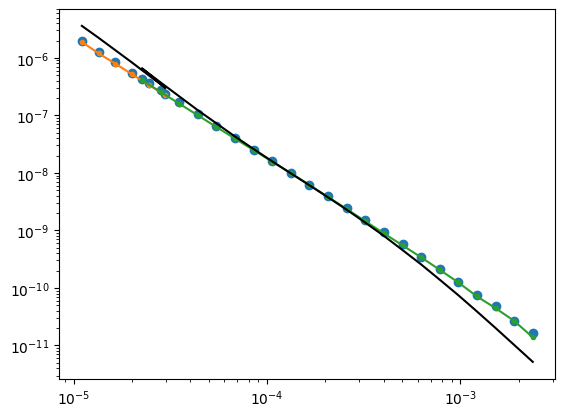

In [10]:
d_obs = torch.from_numpy(dbdt_values).abs()#.log10()

# d_true = 10**torch.concat([fwr(rho, thk) for fwr in fwrs])
# d_time = torch.concat([fwr.times for fwr in fwrs])

plt.figure()
plt.loglog(dmfwr.times, d_obs, 'o', label='Observed Data')
plt.plot(lm.time[14], lm.data[14], '.-')
plt.plot(hm.time[14], hm.data[14], '.-')
plt.plot(dmfwr.times, 10**dmfwr(rho,thk), 'k-', label='True Model')

In [12]:
d_obs = torch.from_numpy(dbdt_values).abs().log10()
d_err = torch.from_numpy(np.log10(1. + error_values/100.))

include_mask = include_values.astype(bool)
d_err[~include_mask] = torch.inf  # Set error to zero for included measurements

inv = fastJac(d_obs, d_err, res_start, dmfwr)
inv.data_misfit_acceptance_threshold = 1.
res_mod = inv.invert(iter_cap=10)

001	misfit:	12.74
002	misfit:	3.41
003	misfit:	1.75
004	misfit:	1.33
005	misfit:	1.12
006	misfit:	0.99
misfit is below 1.0, stopping inversion


In [13]:
d_syn = inv.forward(*res_mod.mod)

In [14]:
d_syn

tensor([ -5.7009,  -5.8922,  -6.0823,  -6.2679,  -6.4561,  -6.6430,  -6.3482,
         -6.5556,  -6.7617,  -6.9703,  -7.1759,  -7.3860,  -7.5927,  -7.8013,
         -8.0081,  -8.2130,  -8.4182,  -8.6187,  -8.8225,  -9.0226,  -9.2302,
         -9.4394,  -9.6595,  -9.8872, -10.1277, -10.3804, -10.6453, -10.9229],
       dtype=torch.float64)

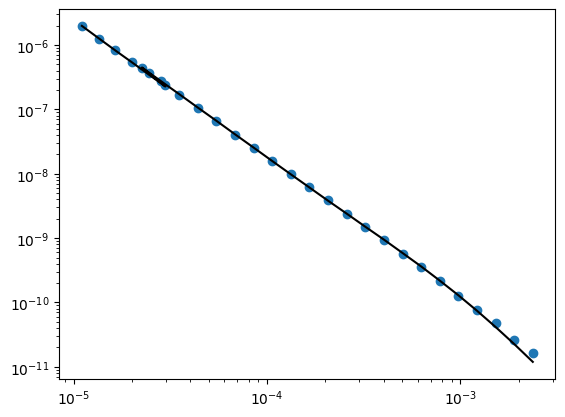

In [15]:
plt.figure()
plt.loglog(dmfwr.times, 10**d_obs, 'o', label='Observed Data')
# plt.plot(lm.time[14], lm.data[14], '.-')
# plt.plot(hm.time[14], hm.data[14], '.-')
plt.plot(dmfwr.times, 10**d_syn, 'k-', label='True Model')

In [16]:
def silence(s):
    pass

data_overview, df_data = usf.sweep2dataframes(sweeps)

df_data['include'] = df_data['inuse_auto']

df_res = df_data.copy()
df_res['dbdt_syn'] = df_res['dbdt']*np.nan

pivot_multi = df_data[df_data['site_id']>-1].pivot_table(
    index=['site_id'],
    columns=['sys_gate'],
    values=['dbdt', 'error', 'include', 'data_id'],
)
pivot_multi.columns = [f'{val}_{col}' for val, col in pivot_multi.columns]

for i,row in pivot_multi.iterrows():


    dbdt_values  = row.filter(like='dbdt_').values
    error_values = row.filter(like='error_').values
    include_values = row.filter(like='include_').values
    data_id = row.filter(like='data_id_').values

    d_obs = torch.from_numpy(dbdt_values).abs().log10()
    d_err = torch.from_numpy(np.log10(1. + error_values/100.))
    include_mask = include_values.astype(bool)
    d_err[~include_mask] = torch.inf  # Set error to zero for included measurements

    inv = fastJac(d_obs, d_err, res_start, dmfwr, logger=silence)
    inv.data_misfit_acceptance_threshold = 1.
    res_mod = inv.invert(iter_cap=3)

    d_syn = 10**inv.forward(*res_mod.mod)
    df_res.loc[data_id, 'dbdt_syn'] = d_syn.numpy()
    print(f'Inversion for data_id {i} completed.')

Inversion for data_id 0 completed.
Inversion for data_id 1 completed.
Inversion for data_id 2 completed.
Inversion for data_id 3 completed.
Inversion for data_id 4 completed.
Inversion for data_id 5 completed.
Inversion for data_id 6 completed.
Inversion for data_id 7 completed.
Inversion for data_id 8 completed.
Inversion for data_id 9 completed.
Inversion for data_id 10 completed.
Inversion for data_id 11 completed.
Inversion for data_id 12 completed.
Inversion for data_id 13 completed.
Inversion for data_id 14 completed.
Inversion for data_id 15 completed.
Inversion for data_id 16 completed.
Inversion for data_id 17 completed.
Inversion for data_id 18 completed.
Inversion for data_id 19 completed.
Inversion for data_id 20 completed.
Inversion for data_id 21 completed.
Inversion for data_id 22 completed.
Inversion for data_id 23 completed.
Inversion for data_id 24 completed.
Inversion for data_id 25 completed.
Inversion for data_id 26 completed.
Inversion for data_id 27 completed.
In

In [16]:
df_res.to_csv('inversion_results.csv')

In [17]:
import plotly.express as px
import plotly.graph_objects as go

# Create scatter plot
fig = px.scatter(
    df_res,
    x='dbdt',
    y='dbdt_syn',
    color='system_id',  # Color by system type
    hover_data=['site_id', 'gate_id', 'time'],  # Additional info on hover
    title='Observed vs Synthetic dB/dt',
    labels={
        'dbdt': 'Observed dB/dt [V/m²]',
        'dbdt_syn': 'Synthetic dB/dt [V/m²]'
    }
)

# Add 1:1 line for reference
min_val = min(df_res['dbdt'].min(), df_res['dbdt_syn'].min())
max_val = max(df_res['dbdt'].max(), df_res['dbdt_syn'].max())

fig.add_trace(
    go.Scatter(
        x=[min_val, max_val],
        y=[min_val, max_val],
        mode='lines',
        name='1:1 line',
        line=dict(color='black', dash='dash')
    )
)

# Set log scale for both axes
fig.update_layout(
    xaxis_type="log",
    yaxis_type="log",
    width=600,
    height=600
)

fig.show()

In [19]:
import pandas as pd
df_res2 = pd.read_csv('inversion_results.csv', index_col=0)

import plotly.express as px
import plotly.graph_objects as go

# Create scatter plot
fig = px.scatter(
    df_res2,
    x='dbdt',
    y='dbdt_syn',
    color='system_id',  # Color by system type
    hover_data=['site_id', 'gate_id', 'time'],  # Additional info on hover
    title='Observed vs Synthetic dB/dt',
    labels={
        'dbdt': 'Observed dB/dt [V/m²]',
        'dbdt_syn': 'Synthetic dB/dt [V/m²]'
    }
)

# Add 1:1 line for reference
min_val = min(df_res['dbdt'].min(), df_res['dbdt_syn'].min())
max_val = max(df_res['dbdt'].max(), df_res['dbdt_syn'].max())

fig.add_trace(
    go.Scatter(
        x=[min_val, max_val],
        y=[min_val, max_val],
        mode='lines',
        name='1:1 line',
        line=dict(color='black', dash='dash')
    )
)

# Set log scale for both axes
fig.update_layout(
    xaxis_type="log",
    yaxis_type="log",
    width=600,
    height=600
)

fig.show()